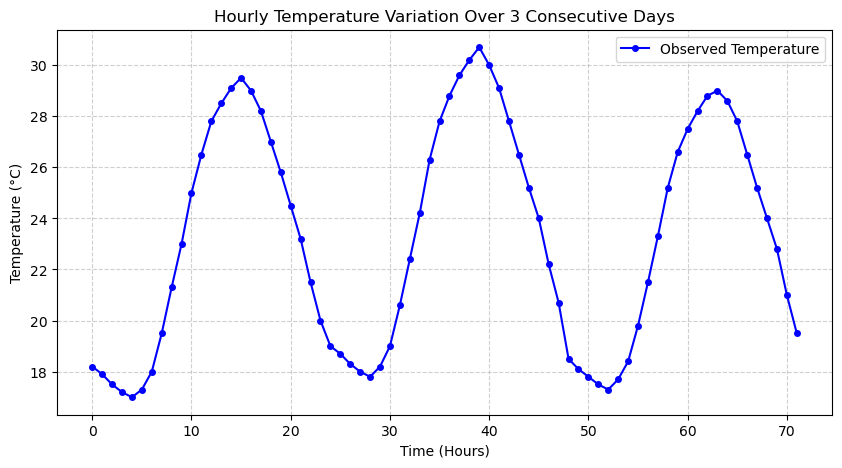

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Setup Time vector from 0 to 71 hours
time = np.arange(0, 72)

# 2. Input temperature data row by row (Day 1, Day 2, Day 3 concatenated)
temperature = np.array([
    # Day 1 (Hours 0-23)
    18.2, 17.9, 17.5, 17.2, 17.0, 17.3, 18.0, 19.5, 21.3, 23.0, 25.0, 26.5, 
    27.8, 28.5, 29.1, 29.5, 29.0, 28.2, 27.0, 25.8, 24.5, 23.2, 21.5, 20.0,
    # Day 2 (Hours 24-47)
    19.0, 18.7, 18.3, 18.0, 17.8, 18.2, 19.0, 20.6, 22.4, 24.2, 26.3, 27.8, 
    28.8, 29.6, 30.2, 30.7, 30.0, 29.1, 27.8, 26.5, 25.2, 24.0, 22.2, 20.7,
    # Day 3 (Hours 48-71)
    18.5, 18.1, 17.8, 17.5, 17.3, 17.7, 18.4, 19.8, 21.5, 23.3, 25.2, 26.6, 
    27.5, 28.2, 28.8, 29.0, 28.6, 27.8, 26.5, 25.2, 24.0, 22.8, 21.0, 19.5
])

# 3. Create the plot
plt.figure(figsize=(10, 5))

# Plot temperature as a continuous line with markers on each hour
plt.plot(time, temperature, color='blue', marker='o', markersize=4, label='Observed Temperature')

plt.title("Hourly Temperature Variation Over 3 Consecutive Days")
plt.xlabel("Time (Hours)")
plt.ylabel("Temperature (°C)")
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

# Display the display output
plt.show()

In [2]:
# Step 2: encontrar los betas por regresion lineal

# Frecuencia angular: ya sabemos que el periodo es 24 horas (Step 1)
omega = 2 * np.pi / 24

# design matrix to plug in  'linear regression formula' (.lstsq). esta matriz tiene estas 3 columnas y 72 filas
X = np.column_stack([
    np.ones_like(time, dtype=float),
    np.sin(omega * time),
    np.cos(omega * time)
])
#linear regression
betas, _, _, _ = np.linalg.lstsq(X, temperature, rcond=None)
beta0, beta1, beta2 = betas

print(f"beta0 = {beta0:.6f}")
print(f"beta1 = {beta1:.6f}")
print(f"beta2 = {beta2:.6f}")

print(f"\nT(t) = {beta0:.4f} + {beta1:.4f}*sin(2*pi*t/24) + {beta2:.4f}*cos(2*pi*t/24)")

beta0 = 23.308333
beta1 = -4.206817
beta2 = -4.510527

T(t) = 23.3083 + -4.2068*sin(2*pi*t/24) + -4.5105*cos(2*pi*t/24)


In [3]:
# Recuperar A (amplitud) y phi (fase) a partir de los betas
A = np.sqrt(beta1**2 + beta2**2)
phi = np.arctan2(beta2, beta1)  #If you use the regular arctan function, it will return an angle in the first quadrant, which would be incorrect
                                #arctan2 takes signs into account

print(f"A = {A:.4f}")
print(f"phi (radians) = {phi:.6f}")
print(f"phi (degrees) = {np.degrees(phi):.2f}")

A = 6.1678
phi (radians) = -2.321369
phi (degrees) = -133.00


In [4]:
# Step 3: R^2 and residual diagnostics

# Model prediction and residuals
temperature_predicted = X @ betas #aca multiplcas las matrices. fijate arriba lo que representaba X. 
                                   #esto es como reemplazar cada time en la formula que obtuvimos haciendo linear regression, o sea T(t)
residuals = temperature - temperature_predicted

# R^2
SS_res = np.sum(residuals**2)
SS_tot = np.sum((temperature - np.mean(temperature))**2)
R2 = 1 - SS_res/SS_tot

print(f"R^2 = {R2:.6f}")

# Residual diagnostics
print(f"\nMean of residuals: {np.mean(residuals):.6f}")
print(f"Standard deviation of residuals: {np.std(residuals):.6f}")
print(f"Minimum residual: {np.min(residuals):.4f}")
print(f"Maximum residual: {np.max(residuals):.4f}")

R^2 = 0.982244

Mean of residuals: 0.000000
Standard deviation of residuals: 0.586387
Minimum residual: -1.1015
Maximum residual: 1.2276


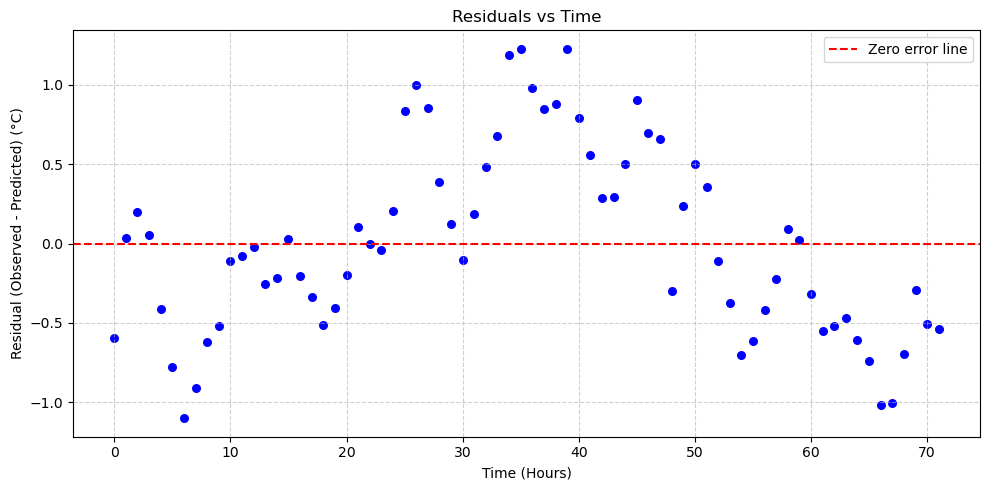

In [5]:
# Residual diagnostics: plot residuals vs time for better analysis
plt.figure(figsize=(10, 5))
plt.scatter(time, residuals, color='blue', marker='o', s=30)
plt.axhline(0, color='red', linestyle='--', linewidth=1.5, label='Zero error line')

plt.title("Residuals vs Time")
plt.xlabel("Time (Hours)")
plt.ylabel("Residual (Observed - Predicted) (°C)")
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.show()

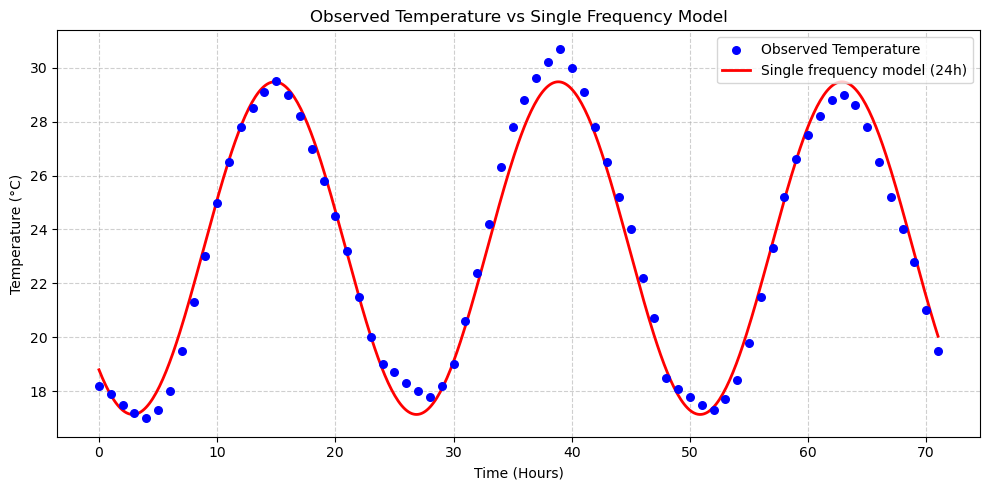

In [6]:
# Observed temperature vs single frequency model (another way of comparing predicted vs observed)
time_continuous = np.linspace(0, 71, 500)
X_continuous = np.column_stack([np.ones_like(time_continuous), 
                                  np.sin(omega*time_continuous), 
                                  np.cos(omega*time_continuous)])
temperature_model_continuous = X_continuous @ betas

plt.figure(figsize=(10, 5))
plt.scatter(time, temperature, color='blue', s=30, label='Observed Temperature', zorder=3)
plt.plot(time_continuous, temperature_model_continuous, color='red', linewidth=2, 
         label='Single frequency model (24h)', zorder=2)

plt.title("Observed Temperature vs Single Frequency Model")
plt.xlabel("Time (Hours)")
plt.ylabel("Temperature (°C)")
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

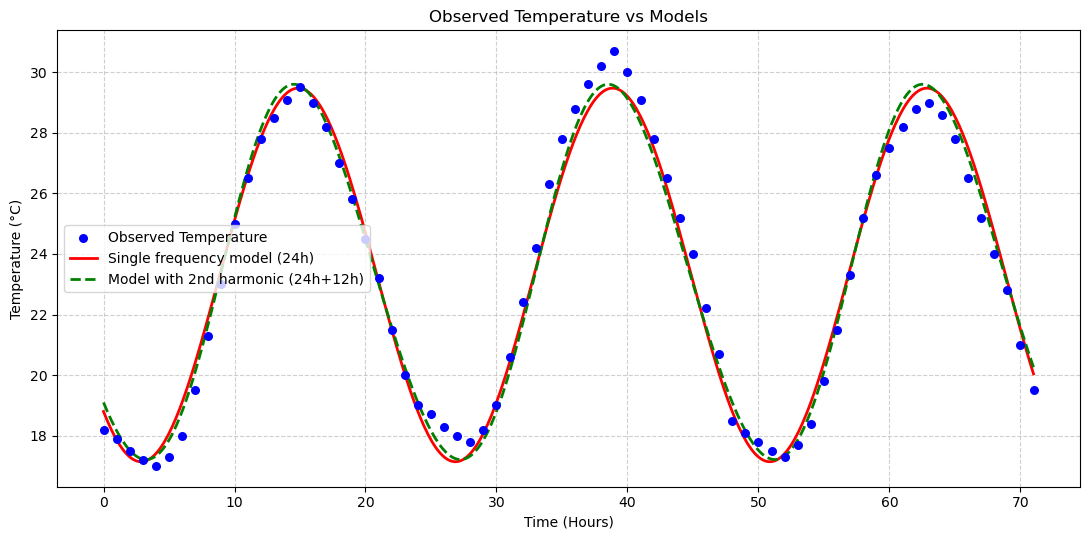

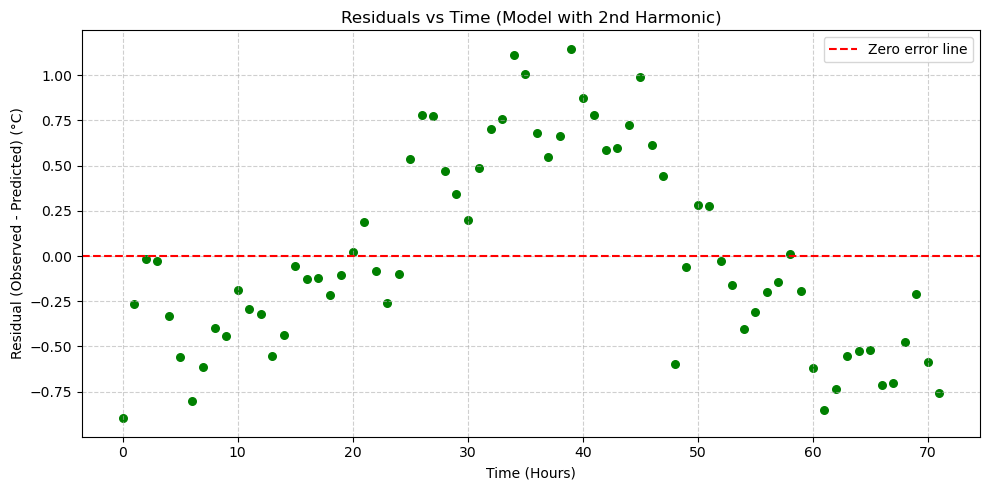

In [7]:
# Modelo con segundo armonico: fundamental (24h) + segundo armonico (12h)
X2 = np.column_stack([
    np.ones_like(time, dtype=float),
    np.sin(omega*time), np.cos(omega*time),
    np.sin(2*omega*time), np.cos(2*omega*time)
])
betas2, _, _, _ = np.linalg.lstsq(X2, temperature, rcond=None)
temperature_predicted_2 = X2 @ betas2
residuals_2 = temperature - temperature_predicted_2

# Curvas continuas para graficar
time_continuous = np.linspace(0, 71, 500)
X1_cont = np.column_stack([np.ones_like(time_continuous), np.sin(omega*time_continuous), np.cos(omega*time_continuous)])
X2_cont = np.column_stack([
    np.ones_like(time_continuous),
    np.sin(omega*time_continuous), np.cos(omega*time_continuous),
    np.sin(2*omega*time_continuous), np.cos(2*omega*time_continuous)
])
temp_model1_cont = X1_cont @ betas
temp_model2_cont = X2_cont @ betas2

# Grafico 1: observado vs ambos modelos
plt.figure(figsize=(11, 5.5))
plt.scatter(time, temperature, color='blue', s=30, label='Observed Temperature', zorder=3)
plt.plot(time_continuous, temp_model1_cont, color='red', linewidth=2, label='Single frequency model (24h)', zorder=2)
plt.plot(time_continuous, temp_model2_cont, color='green', linewidth=2, linestyle='--', label='Model with 2nd harmonic (24h+12h)', zorder=2)
plt.title("Observed Temperature vs Models")
plt.xlabel("Time (Hours)")
plt.ylabel("Temperature (°C)")
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

# Grafico 2: residuos del modelo con 2nd harmonic
plt.figure(figsize=(10, 5))
plt.scatter(time, residuals_2, color='green', marker='o', s=30)
plt.axhline(0, color='red', linestyle='--', linewidth=1.5, label='Zero error line')
plt.title("Residuals vs Time (Model with 2nd Harmonic)")
plt.xlabel("Time (Hours)")
plt.ylabel("Residual (Observed - Predicted) (°C)")
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

In [8]:
# R^2 comparison table: single frequency vs model with 2nd harmonic


def calcular_R2(obs, pred):
    SS_res = np.sum((obs-pred)**2)
    SS_tot = np.sum((obs-np.mean(obs))**2)
    return 1 - SS_res/SS_tot

R2_2 = calcular_R2(temperature, temperature_predicted_2)

# Tabla comparativa
mejora = R2_2 - R2
mejora_porcentual = (mejora/R2)*100

print(f"{'Model':<30} {'R^2':>10}")
print(f"{'-'*42}")
print(f"{'Single frequency (24h)':<30} {R2:>10.4f}")
print(f"{'With 2nd harmonic (24h+12h)':<30} {R2_2:>10.4f}")
print(f"{'-'*42}")
print(f"{'Improvement':<30} {mejora:>10.4f}")
print(f"{'Improvement (%)':<30} {mejora_porcentual:>9.2f}%")

Model                                 R^2
------------------------------------------
Single frequency (24h)             0.9822
With 2nd harmonic (24h+12h)        0.9847
------------------------------------------
Improvement                        0.0025
Improvement (%)                     0.25%


Top 5 dominant frequencies (by power):
  Period (hours) |  Frequency (1/h) |        Power
           24.00 |           0.0417 |     49302.64
           72.00 |           0.0139 |       567.37
           12.00 |           0.0833 |       125.04
            6.00 |           0.1667 |        61.33
           36.00 |           0.0278 |        43.70


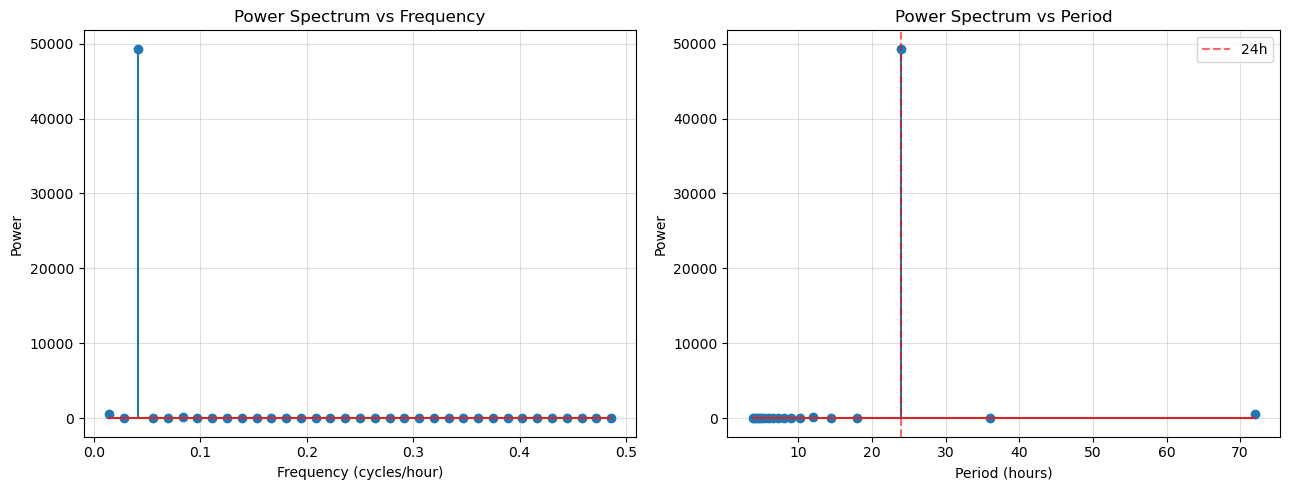

In [9]:
# 5.7: Apply FFT to the temperature dataset and find the power spectrum

n = len(temperature)
fft_temperature = np.fft.fft(temperature)
frequencies = np.fft.fftfreq(n, d=1)  # d=1: samples spaced 1 hour apart

# Power spectrum: the pre-built function to get this is np.abs(fft_result)**2
power_spectrum = np.abs(fft_temperature)**2

# Keep only the positive-frequency half (FFT output is symmetric for real input)
half = n // 2
freqs_positive = frequencies[:half]
power_positive = power_spectrum[:half]

# Convert frequency to period for easier interpretation
periods = np.zeros_like(freqs_positive)
periods[1:] = 1 / freqs_positive[1:]

print("Top 5 dominant frequencies (by power):")
sorted_idx = np.argsort(power_positive[1:])[::-1] + 1
print(f"{'Period (hours)':>16} | {'Frequency (1/h)':>16} | {'Power':>12}")
for idx in sorted_idx[:5]:
    print(f"{periods[idx]:>16.2f} | {freqs_positive[idx]:>16.4f} | {power_positive[idx]:>12.2f}")

# Plot
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].stem(freqs_positive[1:], power_positive[1:])
axes[0].set_title("Power Spectrum vs Frequency")
axes[0].set_xlabel("Frequency (cycles/hour)")
axes[0].set_ylabel("Power")
axes[0].grid(alpha=0.4)

axes[1].stem(periods[1:20], power_positive[1:20])
axes[1].set_title("Power Spectrum vs Period")
axes[1].set_xlabel("Period (hours)")
axes[1].set_ylabel("Power")
axes[1].grid(alpha=0.4)
axes[1].axvline(24, color='red', linestyle='--', alpha=0.6, label='24h')
axes[1].legend()

plt.tight_layout()
plt.show()